# Which options respond to which macro news, and do they charge the right amount?

This notebook walks through the results. It only loads the tables saved in `data/` by the scripts, so it runs in a few seconds and needs no API keys. The README lists the commands that produce those tables.

**Vocabulary used throughout**

- **Release morning**: a trading day with a scheduled 08:30 ET data release (CPI, jobs report, PCE, GDP, retail sales, PPI, jobless claims). **Quiet day**: a day with none of these and no FOMC meeting.
- **Implied variance**: the variance of tomorrow's return that option prices imply. For one-day SPX options it is VIX1D² / 252, in %² (a 1% daily standard deviation is 1 %²).
- **Event premium ("priced")**: implied variance on the evening before a release, minus its level on nearby quiet evenings.
- **Hedged short straddle**: sell a call and a put at the same strike, and hold shares so that the position does not care about direction. What is left is a bet that realized variance will be lower than implied variance. Its profit, in basis points (bp, 0.01%) of the index level, says whether options overcharged (positive) or undercharged (negative).
- **γ (gamma)**: the percent move in SPY per 1% move in TLT (long Treasury bonds) caused by the news, in the 15 minutes after 08:30.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGS = ROOT / "data", ROOT / "figures"
C = {"2022-23": "#D55E00", "2024-26": "#0072B2"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.options.display.float_format = "{:.2f}".format

## 1. When macro news moves bonds, do stocks move with them?

A release that makes investors expect higher interest rates pushes bond prices down. Whether stocks fall with them depends on how the news is read. If it is read as "the Fed will have to tighten", stocks fall too and γ is positive. If it is read as "the economy is strong", stocks hold up and γ is near zero or negative.

γ is estimated by comparing release mornings with quiet mornings (Rigobon and Sack, 2004): the extra co-movement of stocks and bonds on release mornings, divided by the extra variance of bonds. `macro_news.py` computes it with bootstrap intervals.

In [2]:
g = pd.read_csv(DATA / "macro_gamma.csv")
g45 = g[g.window == "w45"]
reg = g45[g45.period.isin(C)].pivot(index="kind", columns="period", values=["gamma", "lo", "hi", "n"])
order = ["CPI", "PPI", "PCE", "JOBS", "GDP", "RETAIL", "TIER1 (all but claims)"]
reg.loc[order].round(2)

gamma              lo              hi          \
period                 2022-23 2024-26 2022-23 2024-26 2022-23 2024-26   
kind                                                                     
CPI                       1.25    0.71    0.75    0.53    1.62    0.95   
PPI                       2.18    0.74   -7.53    0.34   14.03    1.73   
PCE                      -0.03    0.43   -2.04    0.05    1.85    0.70   
JOBS                      0.89    0.10    0.60   -0.17    1.39    0.34   
GDP                       0.29    0.23   -0.26   -0.05    0.81    0.52   
RETAIL                    0.01   -0.35   -0.23   -0.86    0.36    0.01   
TIER1 (all but claims)    0.86    0.35    0.53    0.17    1.14    0.52   

                             n          
period                 2022-23 2024-26  
kind                                    
CPI                      21.00   34.00  
PPI                      16.00   29.00  
PCE                      20.00   33.00  
JOBS                     19.00   33.00  
GDP                      21.00   20.00  
RETAIL                   21.00   34.00  
TIER1 (all but claims)  118.00  183.00

`lo` and `hi` are the 95% interval. Where the interval is very wide (PPI and PCE in 2022–23) the release did not move bonds enough beyond a quiet morning to identify γ, and the point estimate should be ignored.

In 2022–23 the major releases all have a clearly positive γ. In 2024–26 the inflation releases (CPI, PPI, PCE) still do, at roughly half the 2022–23 level, while the jobs report has fallen to about zero.

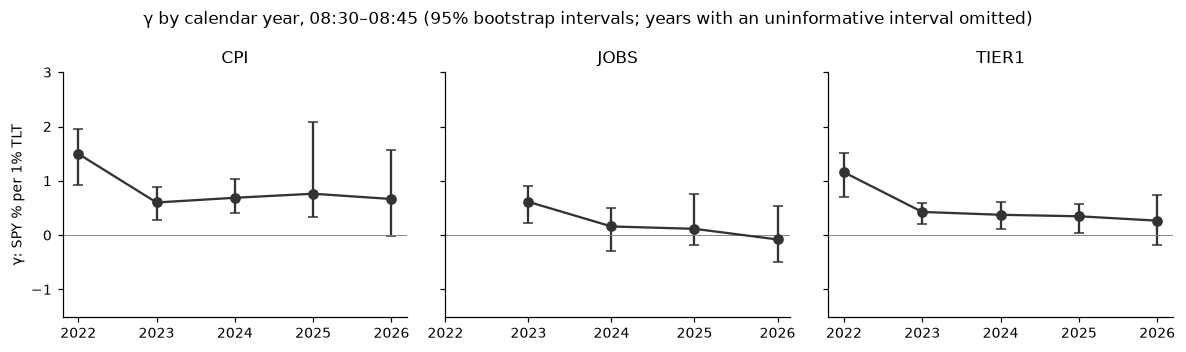

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for a, k in zip(ax, ["CPI", "JOBS", "TIER1 (all but claims)"]):
    x = g45[(g45.kind == k) & g45.period.str.fullmatch(r"\d{4}")].dropna(subset=["gamma"])
    x = x[(x.hi - x.lo) < 6]          # drop years where the interval is too wide to be informative
    yrs = x.period.astype(int)
    lo, hi = x.lo.clip(lower=-1.5), x.hi.clip(upper=3)
    a.errorbar(yrs, x.gamma, yerr=[(x.gamma - lo).clip(lower=0), (hi - x.gamma).clip(lower=0)], fmt="o-", capsize=3, color="#333333")
    a.axhline(0, c="grey", lw=0.6); a.set_title(k.split(" (")[0]); a.set_xticks(range(2022, 2027))
ax[0].set_ylabel("γ: SPY % per 1% TLT"); ax[0].set_ylim(-1.5, 3)
fig.suptitle("γ by calendar year, 08:30–08:45 (95% bootstrap intervals; years with an uninformative interval omitted)"); fig.tight_layout()

The break is between 2022 and 2023, not at the start of 2024. Single-year estimates rest on 8 to 13 releases each, so the pooled series ("TIER1", all releases except claims) is the one to read: 1.16, 0.43, 0.37, 0.35, 0.27.

## 2. What do options charge for each release?

In [4]:
A = pd.read_csv(DATA / "event_options_A.csv")
A["t"] = A.priced / A.priced_se
A.pivot(index="release", columns="regime", values=["priced", "t", "n"]).loc[["CPI", "FOMC", "JOBS", "PCE", "GDP", "RETAIL", "PPI", "CLAIMS"]]

priced               t               n        
regime  2022-23 2024-26 2022-23 2024-26 2022-23 2024-26
release                                                
CPI        1.97    0.38    4.30    5.57   20.00   33.00
FOMC       1.41    0.27    4.70    2.82   13.00   22.00
JOBS       0.71    0.46    4.78    5.33   18.00   32.00
PCE        0.31    0.16    3.18    2.56   20.00   33.00
GDP        0.04    0.58    0.55    1.42   22.00   19.00
RETAIL     0.15   -0.10    1.56   -1.66   20.00   32.00
PPI        0.40    0.06    1.93    1.28   13.00   27.00
CLAIMS     0.12    0.03    2.17    0.57   48.00   80.00

`priced` is the event premium in one-day SPX implied variance (%²). Four releases carry a significant premium: CPI, FOMC, jobs and PCE. The CPI premium fell about fivefold between the two periods; the jobs premium fell by about a third, so the two are now similar.

## 3. Did options charge the right amount?

The test is the hedged short straddle. If options charge correctly for releases, selling on a release eve should earn about the same as selling on a quiet eve.

In [5]:
D = pd.read_csv(DATA / "event_options_D.csv")
v = D[D.sym == "SPY@VIX1D"].copy(); v["t"] = v["diff"] / v.se
v[["period", "n_release", "n_quiet", "release", "quiet", "diff", "t", "rv_iv_release", "rv_iv_quiet"]]

,period,n_release,n_quiet,release,quiet,diff,t,rv_iv_release,rv_iv_quiet
0,2022-23,174,235,-3.21,14.05,-17.26,-3.14,0.95,0.77
1,2024-26,278,426,7.25,7.81,-0.56,-0.17,0.74,0.77
2,2022,68,91,-6.03,11.57,-17.60,-1.64,1.07,0.84
3,2023,106,144,-1.40,15.62,-17.02,-2.93,0.75,0.66
4,2024,107,145,1.77,7.31,-5.55,-0.95,0.89,0.82
5,2025,88,155,12.18,4.83,7.35,1.18,0.57,0.78
6,2026,83,126,9.10,12.06,-2.96,-0.62,0.78,0.71


`release` and `quiet` are the seller's average profit in bp; `diff` is release minus quiet. `rv_iv` is realized variance divided by implied variance.

In 2022–23 sellers earned 17 bp less on release eves than on quiet eves (t about −3): release days delivered 95% of the variance options had priced, quiet days only 77%. Options were too cheap before releases relative to quiet days. In 2024–26 the difference is zero.

These numbers price the straddle at VIX1D. The next section shows why only the difference between release and quiet eves should be trusted.

## 4. Traded option prices (from February 2024)

In [6]:
spy = pd.read_csv(DATA / "straddle_real_oc.csv", parse_dates=["date"])
print("Traded at-the-money vol / VIX1D, mean:", round(spy.ratio.mean(), 3))
print("Seller's profit on all eves, bp:  traded prices", round(spy.pnl_bp.mean(), 1), "| same trades priced at VIX1D", round(spy.pnl_vix_bp.mean(), 1))
t = D[D.sym.isin(["SPY", "QQQ", "IWM"])].copy(); t["t"] = t["diff"] / t.se
t[["sym", "period", "n_release", "release", "quiet", "diff", "t"]]

Traded at-the-money vol / VIX1D, mean: 0.945
Seller's profit on all eves, bp:  traded prices 1.9 | same trades priced at VIX1D 6.0


,sym,period,n_release,release,quiet,diff,t
7,SPY,all releases,264,4.20,3.26,0.94,0.27
8,SPY,"inflation (CPI, PPI, PCE)",89,6.71,3.26,3.45,0.92
9,SPY,"activity (JOBS, RETAIL, GDP, CLAIMS)",154,1.42,3.26,-1.84,-0.40
10,SPY,FOMC,21,13.93,3.26,10.66,0.71
11,QQQ,all releases,264,4.01,1.62,2.39,0.50
12,QQQ,"inflation (CPI, PPI, PCE)",90,6.12,1.62,4.51,0.83
13,QQQ,"activity (JOBS, RETAIL, GDP, CLAIMS)",153,0.26,1.62,-1.36,-0.21
14,QQQ,FOMC,21,22.24,1.62,20.62,1.27
15,IWM,all releases,253,10.96,4.07,6.90,1.26
16,IWM,"inflation (CPI, PPI, PCE)",86,16.14,4.07,12.08,1.77


VIX1D sits about 6% above the volatility at which at-the-money SPY options actually trade. Pricing at VIX1D therefore hands the seller a few bp a day that do not exist. At traded prices the quiet-eve profit is 2 to 4 bp in all three ETFs and not distinguishable from zero, and release eves are no different from quiet eves in SPY and QQQ. IWM (small caps) shows a larger seller's profit before inflation releases, at t about 1.8, which is a lead and not a result.

In [7]:
Cc = pd.read_csv(DATA / "event_options_C.csv")
Cc[Cc.release.isin(["CPI", "JOBS", "FOMC", "PCE"])].pivot(index="release", columns="sym", values="priced")[["SPY", "QQQ", "IWM"]]

sym,SPY,QQQ,IWM
release,,,
CPI,0.44,0.67,1.87
FOMC,0.39,0.70,1.68
JOBS,0.52,0.84,1.59
PCE,0.14,0.46,0.42


The event premium by underlying, in %². IWM options price CPI, jobs and FOMC three to four times as heavily as SPY options in absolute terms, and about twice as heavily relative to IWM's own quiet-day variance.

## 5. CPI, with a prediction market as an outside check

For CPI, Kalshi lists contracts of the form "core CPI will be above k". Their prices give the market's probability distribution of the print the evening before: its mean, and its standard deviation σ_K. The **surprise** is the actual print minus that mean. With the stock reaction written as r = β·surprise + noise, options should charge about β²·σ_K² for the surprise, which lets us ask whether options assume the right β.

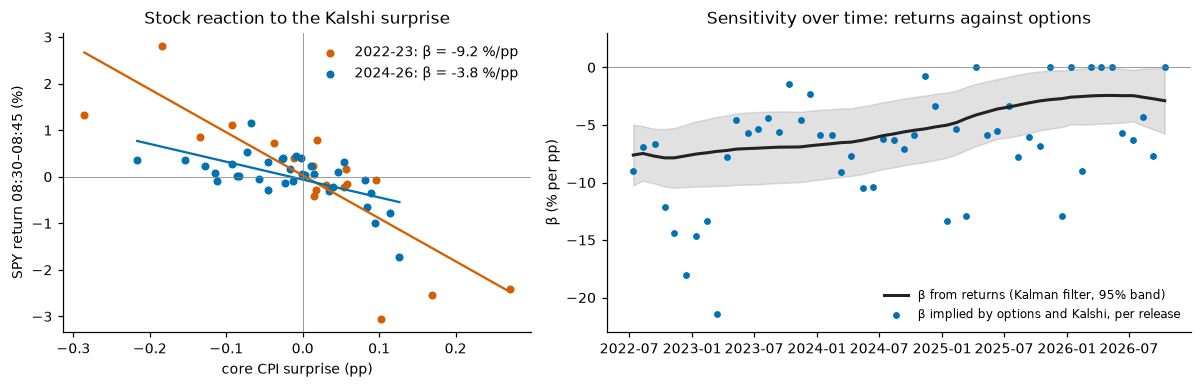

In [14]:
p = pd.read_csv(DATA / "ss_panel_win45.csv", parse_dates=["date"])
p["reg"] = np.where(p.date < "2024-01-01", "2022-23", "2024-26")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
for r_, x in p.groupby("reg"):
    x = x.dropna(subset=["s", "r_obs"]); b = np.polyfit(x.s, x.r_obs, 1)
    ax[0].scatter(x.s, x.r_obs, s=18, color=C[r_], label=f"{r_}: β = {b[0]:.1f} %/pp")
    xx = np.array([x.s.min(), x.s.max()]); ax[0].plot(xx, np.polyval(b, xx), color=C[r_])
ax[0].axhline(0, c="grey", lw=0.5); ax[0].axvline(0, c="grey", lw=0.5); ax[0].legend(frameon=False)
ax[0].set(xlabel="core CPI surprise (pp)", ylabel="SPY return 08:30–08:45 (%)", title="Stock reaction to the Kalshi surprise")
ax[1].fill_between(p.date, p.beta_s - 1.96 * p.beta_s_sd, p.beta_s + 1.96 * p.beta_s_sd, color="#888888", alpha=0.25)
ax[1].plot(p.date, p.beta_s, color="#222222", lw=2, label="β from returns (Kalman filter, 95% band)")
ax[1].scatter(p.date, p.beta_impl_signed, s=12, color="#0072B2", label="β implied by options and Kalshi, per release")
ax[1].axhline(0, c="grey", lw=0.5); ax[1].set_ylim(-23, 3); ax[1].legend(frameon=False, fontsize=8, loc="lower right")
ax[1].set(ylabel="β (% per pp)", title="Sensitivity over time: returns against options"); fig.tight_layout()

Left: the slope is β. Stocks fell about 9% per percentage point of CPI surprise in 2022–23 and about 4% in 2024–26, both clearly different from zero.

Right: the line is β estimated from returns alone. Each dot is the β that option prices and Kalshi's σ_K together imply for one release. The dots scatter around the line with no systematic gap, which is what correct pricing of the sensitivity looks like. Individual dots are very noisy.

In [9]:
r = pd.read_csv(DATA / "rates_channel_panel.csv", parse_dates=["date"])
rows = []
for lab, x in [("2022-23", r[r.period == "2021-23"]), ("2024-26", r[r.period == "2024-26"])]:
    x = x.dropna(subset=["s", "TLT45", "spy45"])
    delta, beta = np.polyfit(x.s, x.TLT45, 1)[0], np.polyfit(x.s, x.spy45, 1)[0]
    rows.append(dict(period=lab, n=len(x), bond_per_pp=delta, stock_per_pp=beta, stock_per_bond=beta / delta))
pd.DataFrame(rows).set_index("period")

,n,bond_per_pp,stock_per_pp,stock_per_bond
period,,,,
2022-23,18,-6.28,-9.24,1.47
2024-26,34,-5.12,-3.83,0.75


The same decomposition with Kalshi as the measuring stick: a percentage point of CPI surprise still moves bonds almost as much as before (−6.3% to −5.1% on TLT), but stocks move half as much per unit of that bond move (1.47 to 0.75). This agrees with the Kalshi-free estimate in section 1 (1.25 to 0.71).

Two checks on this chapter are saved as tables: `placebo.csv` (moving each CPI release to nearby non-event days gives an implied sensitivity near zero in 2022–23, and about 3 from noise alone in 2024–26). In the placebo table `beta_hat` uses the overnight return, which is why the real 2024–26 value is smaller than the 15-minute estimate above and `spread_filter.csv` (Kalshi's distribution is about 1.25 times too wide, and that does not depend on the quote filter).

In [10]:
pl = pd.read_csv(DATA / "placebo.csv")
real = pl[pl.k == 0].set_index("period")[["beta_hat", "ev_mean", "beta_impl"]]
plac = pl[pl.k != 0].groupby("period")[["beta_hat", "ev_mean", "beta_impl"]].median()
pd.concat({"real": real, "placebo median": plac}, axis=1).loc[["2021-23", "2024-26"]]

real                   placebo median                  
        beta_hat ev_mean beta_impl       beta_hat ev_mean beta_impl
period                                                             
2021-23    -9.83    2.07      9.33          -0.02    0.00      0.41
2024-26    -1.96    0.33      5.62           0.61    0.10      3.13

## 6. Summary figure

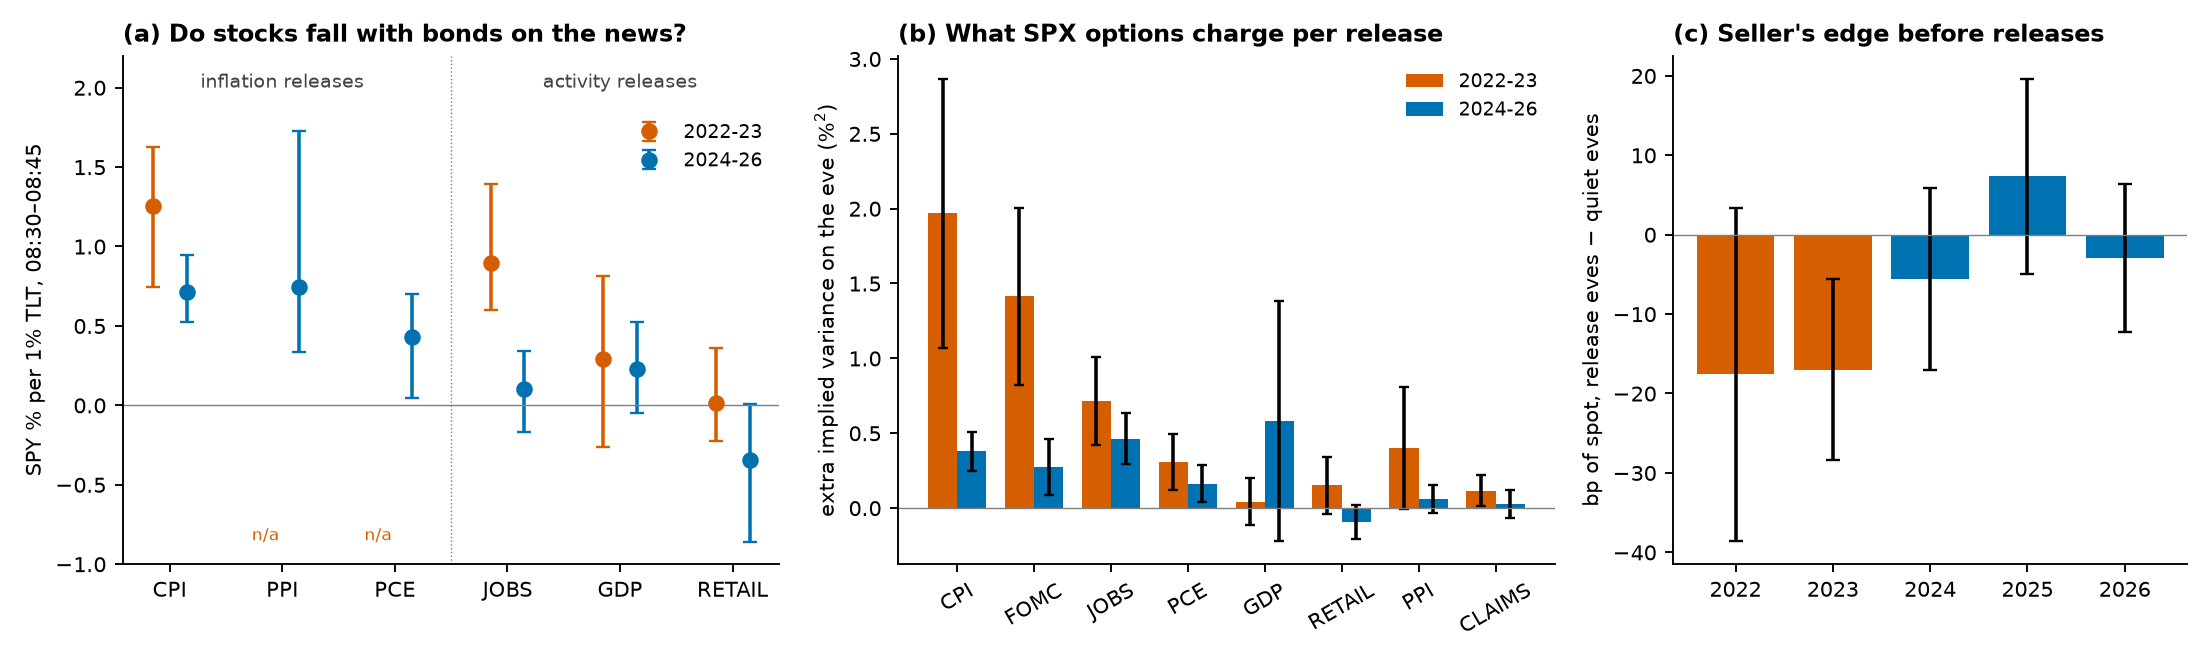

In [11]:
display(Image(str(FIGS / "summary.png"), width=1000))

**What the project supports**

1. The stock–bond link on macro news more than halved after 2022 (0.86 to 0.35).
2. Since then it holds for inflation news (0.66) and not for activity news (0.05).
3. Options price four releases as events and repriced them: the CPI premium fell about fivefold.
4. In 2022–23 one-day options undercharged for release days relative to quiet days (−17 bp, t −3.1); the gap closed by 2024.
5. At traded prices there is no ordinary-day premium to selling one-day options in SPY, QQQ or IWM.

**What it does not support**: a tradeable edge in 2024–26, or any claim about a single release type and underlying taken alone. The limitations are listed in the README.